# Kernel Methods for Machine Learning — Kernel Ridge Regression

The training and test data files (`Xtr_vectors.csv`, `Ytr.csv`, `Xte_vectors.csv`).

In [102]:
pwd

'/Users/paulsanyang/Desktop/Github_file/Kernel Methods for Machine Learning'

In [70]:
import numpy as np
import pandas as pd

In [72]:
import matplotlib.pyplot as plt

## Load dataset

In [75]:
X_train_vec = pd.read_csv("Xtr_vectors.csv")
Y_train_vec = pd.read_csv("Ytr.csv")
X_test_vec =  pd.read_csv("Xte_vectors.csv")

In [78]:
x_test=X_test_vec.copy()

In [80]:
x_test

,Id,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
0,1,0.0000,0.0312,0.1094,0.0156,0.0156,0.1250,0.0781,0.0000,0.0312,...,0.0625,0.0312,0.0156,0.1094,0.0781,0.0469,0.0312,0.0156,0.0312,0.0625
1,2,0.1562,0.1562,0.0469,0.0469,0.0938,0.1406,0.1250,0.0625,0.1094,...,0.1094,0.1250,0.0469,0.0000,0.0781,0.1094,0.1094,0.1562,0.1250,0.1406
2,3,0.0625,0.0625,0.1094,0.1250,0.0781,0.0938,0.0781,0.0625,0.1250,...,0.0469,0.1250,0.1094,0.0156,0.0312,0.1250,0.1719,0.0781,0.1094,0.2031
3,4,0.1250,0.0156,0.1562,0.0156,0.0625,0.0312,0.0469,0.0938,0.0938,...,0.0625,0.0469,0.0156,0.1250,0.0938,0.0312,0.0781,0.0938,0.0625,0.0625
4,5,0.0938,0.0625,0.1406,0.1250,0.1406,0.0781,0.0625,0.1250,0.1406,...,0.0312,0.0625,0.0781,0.0469,0.0156,0.0625,0.2031,0.0625,0.0781,0.1406
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,0.1562,0.1406,0.0625,0.0781,0.0625,0.0156,0.1094,0.0938,0.1094,...,0.0625,0.0312,0.0781,0.0625,0.1562,0.0625,0.0625,0.1094,0.0625,0.0938
996,997,0.0781,0.1094,0.1094,0.1562,0.1562,0.0312,0.0781,0.0312,0.0781,...,0.0938,0.0625,0.0625,0.0312,0.0938,0.1562,0.1875,0.0781,0.1406,0.0469
997,998,0.0781,0.0625,0.0781,0.0469,0.0312,0.0938,0.0312,0.0938,0.0312,...,0.0469,0.0781,0.0469,0.0781,0.1250,0.0469,0.0469,0.0781,0.1250,0.0312
998,999,0.0781,0.0781,0.0938,0.0312,0.0469,0.0938,0.0469,0.0625,0.0938,...,0.1406,0.0625,0.0312,0.0781,0.0312,0.0469,0.0469,0.0156,0.0312,0.0469


In [82]:
type(x_test)

pandas.core.frame.DataFrame

In [84]:
x_test.columns

Index(['Id', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24',
       '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36',
       '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48',
       '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60',
       '61', '62', '63', '64'],
      dtype='object')

In [86]:
X_train_vec.head()

,Id,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
0,1,0.1406,0.0625,0.0781,0.1094,0.0625,0.0312,0.0312,0.1406,0.0781,...,0.0625,0.1719,0.0781,0.0312,0.0625,0.1719,0.0781,0.1094,0.1406,0.1250
1,2,0.1250,0.1250,0.0781,0.0938,0.0625,0.0469,0.0625,0.1094,0.1406,...,0.0781,0.1406,0.1094,0.0625,0.0312,0.1406,0.0625,0.1406,0.1250,0.1406
2,3,0.1406,0.1719,0.0156,0.0781,0.1406,0.1094,0.0938,0.0469,0.0312,...,0.1406,0.0938,0.0938,0.0156,0.0625,0.0781,0.1562,0.0469,0.0781,0.1094
3,4,0.1406,0.0938,0.0781,0.1250,0.1250,0.0469,0.0312,0.0781,0.0938,...,0.0312,0.2031,0.1094,0.0469,0.0469,0.1875,0.1094,0.1562,0.1406,0.1875
4,5,0.2188,0.1094,0.1094,0.2031,0.1250,0.0625,0.0156,0.1094,0.1406,...,0.0312,0.0938,0.0781,0.0156,0.0312,0.1250,0.1719,0.0781,0.0625,0.1719


In [88]:
print(X_train_vec.shape)
print(Y_train_vec.shape)
print(X_test_vec.shape)

(2000, 65)
(2000, 2)
(1000, 65)


In [90]:
X_train_vec = X_train_vec.drop("Id", axis = 1).values
Y_train_vec = Y_train_vec.drop("Id", axis = 1).values
X_test_vec =  X_test_vec.drop("Id", axis = 1).values

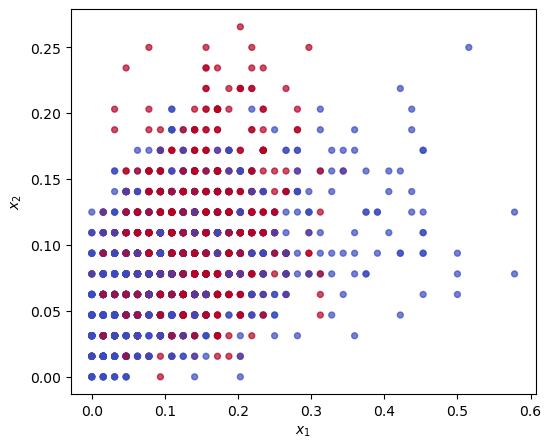

In [98]:
# Visualize data
def plot_data(X, y):
    plt.figure(figsize=(6,5))
    plt.scatter(X[:, 0], X[:, 1], c=np.asarray(y).ravel(), cmap="coolwarm", s=18, alpha=0.7)
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.show()
    
plot_data(X_train_vec, Y_train_vec)

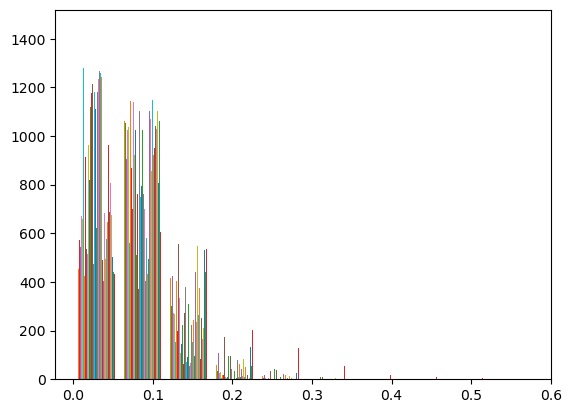

In [94]:
plt.hist(X_train_vec)
plt.show()

In [27]:
# Prediction error
def error(ypred, ytrue):
    e = (ypred != ytrue).mean()
    return e

def add_column_ones(X):
    n = X.shape[0]
    return np.hstack([X, np.ones((n, 1))])

# Visualization
# References: https://scikit-learn.org/stable/auto_examples/svm/plot_iris.html
def make_meshgrid(x, y, h=.02):
    """Create a mesh of points to plot in

    Parameters
    ----------
    x: data to base x-axis meshgrid on
    y: data to base y-axis meshgrid on
    h: stepsize for meshgrid, optional

    Returns
    -------
    xx, yy : ndarray
    """
    x_min, x_max = x.min() - 1, x.max() + 1
    y_min, y_max = y.min() - 1, y.max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    return xx, yy

def plot_contours(classifier, xx, yy, add_intercept=False, **params):
    """Plot the decision boundaries for a classifier.
    
    Parameters
    ----------
    ax: matplotlib axes object
    clf: a classifier
    xx: meshgrid ndarray
    yy: meshgrid ndarray
    params: dictionary of params to pass to contourf, optional
    """
    X = np.c_[xx.ravel(), yy.ravel()]
    Z = classifier.predict(X)#, fit_intercept=add_intercept)
    Z = Z.reshape(xx.shape)
    out = plt.contourf(xx, yy, Z, **params)
    return out

def plot_decision_function(classifier, X_train, y_train, title='', add_intercept=False):
    fig = plt.figure(figsize=(8,7))
    X0, X1 = X_train[:, 0], X_train[:, 1]
    xx, yy = make_meshgrid(X0, X1)
    plot_contours(classifier, xx, yy, cmap=plt.cm.GnBu, alpha=0.5, add_intercept=add_intercept)
    plt.scatter(X0, X1, c=np.asarray(y_train).ravel(), cmap=plt.cm.GnBu, s=20, edgecolors='k')
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.title(title)
    plt.show()

In [29]:
X_test_vec.shape

(1000, 64)

In [31]:
def rbf_kernel_element_wise(x, y, sigma=1):
    '''
    returns the RBF (Gaussian) kernel k(x, y)
    
    Input:
    ------
    x and y are p-dimensional vectors 
    '''
    dist = x - y
    squared_norm = np.dot(dist, dist)
    K = np.exp(-squared_norm / (2 * sigma ** 2))
    return K

In [33]:
def rbf_kernel(X1, X2, sigma=10):
    '''
    Returns the kernel matrix K(X1_i, X2_j): size (n1, n2)
    
    Input:
    ------
    X1: an (n1, p) matrix
    X2: an (n2, p) matrix
    '''
    # For loop with rbf_kernel_element works but is slow in python
    # Use matrix operations!
    X2_norm = np.sum(X2 ** 2, axis = -1)
    X1_norm = np.sum(X1 ** 2, axis = -1)
    gamma = 1 / (2 * sigma ** 2)
    K = np.exp(- gamma * (X1_norm[:, None] + X2_norm[None, :] - 2 * np.dot(X1, X2.T)))
    return K

In [35]:
def sigma_from_median(X, max_samples=500, random_state=0):
    """Median of nonzero pairwise Euclidean distances (sampled for efficiency)."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(random_state)
    if len(X) > max_samples:
        X = X[rng.choice(len(X), max_samples, replace=False)]
    squared = np.sum(X * X, axis=1)
    d2 = np.maximum(squared[:, None] + squared[None, :] - 2 * X @ X.T, 0)
    distances = np.sqrt(d2[np.triu_indices(len(X), k=1)])
    distances = distances[distances > 0]
    if not distances.size:
        raise ValueError("Cannot estimate sigma: no nonzero pairwise distances")
    return float(np.median(distances))

In [37]:
class KernelRidge():
    '''
    Kernel Ridge Regression
    
    Methods
    ----
    fit
    predict
    '''
    def __init__(self, sigma=None, lambd=0.1):
        self.kernel = rbf_kernel
        self.sigma = sigma
        self.lambd = lambd

    def fit(self, X, y):
        n, p = X.shape
        assert (n == len(y))
    
        self.X_train = X
        
        # Compute default sigma from data
        if self.sigma is None:
            self.sigma = sigma_from_median(X)
        
        A = self.kernel(X, X, sigma=self.sigma) +  n*self.lambd * np.eye(n)
        
        ## self.alpha = (K + n lambda I)^-1 y
        # Solution to A x = y
        self.alpha = np.linalg.solve(A , y)

        return self
        
    def predict(self, X):
        # Prediction rule: 
        K_x = self.kernel(X, self.X_train, sigma=self.sigma)
        return K_x @ self.alpha

In [39]:
# To calculate classification accuracy (works with column-vector labels).
def accuracy(y_pred, y_valid):
    y_pred = np.asarray(y_pred).ravel()
    y_valid = np.asarray(y_valid).ravel()
    if y_pred.shape != y_valid.shape:
        raise ValueError("Predictions and labels must have matching shapes")
    return f"The accuracy is: {100 * np.mean(y_pred == y_valid):.2f}%"

In [64]:
# x_train_tune = X_train_vec[:1500,:]
# y_train_tune = Y_train_vec[:1500,:]
# x_test_tune = X_train_vec[1500:,:]
# y_test_tune = Y_train_vec[1500:,:]

In [66]:
# for sig in range(1,40):  
#     model = KernelRidge(sigma = 0.18, lambd = 0.0001)
#     model.fit(x_train_tune,y_train_tune)
#     y_pred = model.predict(x_test_tune)
#     prediction = np.array([0 if i < 0.5 else 1 for i in y_pred]).reshape(len(y_pred),1)
#     print(sig/100,accuracy(prediction, y_test_tune))

In [68]:
# model = KernelRidge(sigma=0.18, lambd=0.0001)
# model.fit(X_train_vec, Y_train_vec)
# y_pred = model.predict(X_test_vec)
# print("Test input shape:", X_test_vec.shape)
# print("Prediction shape:", y_pred.shape)

In [48]:
# plt.figure(figsize=(8, 6))
# plt.scatter(x_train_tune, y_train_tune)
# plt.plot(x_test_tune, y_pred)
# plt.xlabel('$x$')
# plt.ylabel('$y$')
# plt.title('Kernel Ridge Regression, kernel={}, $\lambda=${}'.format(rbf_kernel, lambd))
# plt.show()

## Predictions

In [104]:
prediction = np.array([0 if i < 0.5 else 1 for i in y_pred]).reshape(len(y_pred),1)
# prediction

In [100]:
# accuracy(prediction, y_test_tune)

In [54]:
 #prediction

In [56]:
# data frame for iD
iD = pd.DataFrame(x_test.Id)
# iD

In [58]:
#data frame for prediction
pred = pd.DataFrame(prediction, columns = ["Covid"])

In [60]:
#stack the data frame for id and pred
result = pd.DataFrame(np.hstack([iD,pred]), columns = ["ID", "Covid"])

In [62]:
result.to_csv("Sene_Sanyang.csv", index=False)

## Sanity checks

The following cells **do not change the fitted model**. They illustrate the geometry of the RBF kernel and the dataset. The kernel is

$$k(x,z)=\exp\left(-\frac{\lVert x-z\rVert^2}{2\sigma^2}\right).$$


In [78]:
# Basic mathematical consistency checks (no dataset needed)
a = np.array([0.0, 1.0, 2.0])
b = np.array([1.0, 0.0, 2.0])
for sigma in (0.2, 1.0, 3.0):
    element = rbf_kernel_element_wise(a, b, sigma=sigma)
    matrix = rbf_kernel(a[None, :], b[None, :], sigma=sigma)[0, 0]
    assert np.isclose(element, matrix), (sigma, element, matrix)
assert np.isclose(rbf_kernel_element_wise(a, a), 1.0)
print("RBF element-wise and vectorized implementations agree.")

RBF element-wise and vectorized implementations agree.


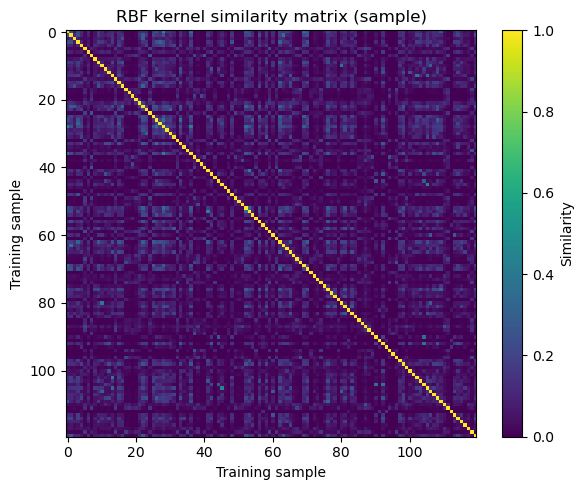

In [80]:
# Visualize the kernel matrix for a small subset to keep the plot responsive
sample_count = min(120, len(X_train_vec))
X_subset = X_train_vec[:sample_count]
K_subset = rbf_kernel(X_subset, X_subset, sigma=0.18)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(K_subset, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set(title="RBF kernel similarity matrix (sample)", xlabel="Training sample", ylabel="Training sample")
fig.colorbar(im, ax=ax, label="Similarity")
plt.tight_layout()
plt.show()

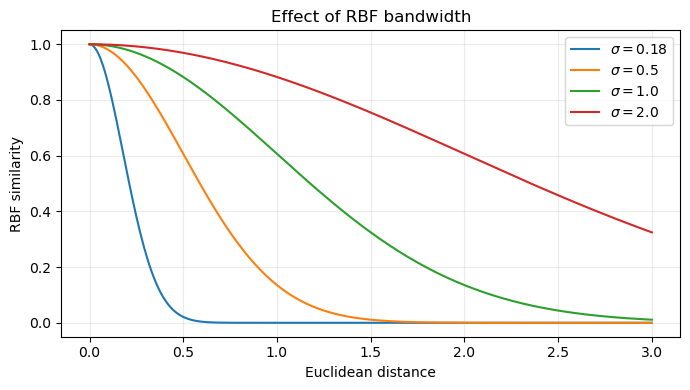

In [82]:
# Explore how the RBF bandwidth affects similarity as a function of distance
d = np.linspace(0, 3, 300)
fig, ax = plt.subplots(figsize=(7, 4))
for sigma in (0.18, 0.5, 1.0, 2.0):
    ax.plot(d, np.exp(-d**2 / (2 * sigma**2)), label=fr"$\sigma={sigma}$")
ax.set(xlabel="Euclidean distance", ylabel="RBF similarity", title="Effect of RBF bandwidth")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

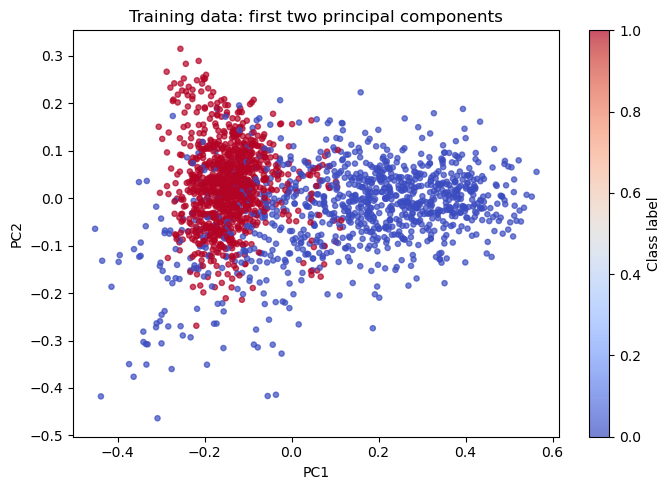

In [84]:
# PCA visualization of the first two principal directions (NumPy-only)
# This is an exploratory 2D projection, not the model's decision boundary
max_points = min(2000, len(X_train_vec))
X_vis = np.asarray(X_train_vec[:max_points], dtype=float)
y_vis = np.asarray(Y_train_vec[:max_points]).ravel()
X_centered = X_vis - X_vis.mean(axis=0)
# Use an eigen-decomposition of the sample Gram matrix if features outnumber samples
if X_centered.shape[1] > X_centered.shape[0]:
    G = X_centered @ X_centered.T
    eigenvalues, eigenvectors = np.linalg.eigh(G)
    order = np.argsort(eigenvalues)[::-1][:2]
    coords = eigenvectors[:, order] * np.sqrt(np.maximum(eigenvalues[order], 0))
else:
    _, _, vt = np.linalg.svd(X_centered, full_matrices=False)
    coords = X_centered @ vt[:2].T
if coords.shape[1] < 2:
    coords = np.pad(coords, ((0, 0), (0, 2 - coords.shape[1])))
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(coords[:, 0], coords[:, 1], c=y_vis, cmap="coolwarm", s=14, alpha=0.7)
ax.set(title="Training data: first two principal components", xlabel="PC1", ylabel="PC2")
fig.colorbar(sc, ax=ax, label="Class label")
plt.tight_layout()
plt.show()